In [1]:
import torch
from model import SpatialR3d18
import matplotlib.pyplot as plt
import numpy as np
from collections import OrderedDict
import matplotlib as mpl
import seaborn as sns
from scipy.interpolate import CubicSpline
from scipy import interpolate
from scipy.ndimage import gaussian_filter

sns.set_style('white')
color_palette = sns.color_palette('colorblind')
sns.set_palette(color_palette)
plt.rcParams.update({
    'figure.dpi': 150,
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'lines.linewidth': 2,
    'axes.grid': True,
    'grid.linestyle': '--',
    'grid.alpha': 0.25
})

def remove_prefix(original_dict, prefix):
    new_dict = OrderedDict()
    for key, value in original_dict.items():
        if key.startswith(prefix):
            new_key = key[len(prefix):]
        new_dict[new_key] = value
    return new_dict

In [2]:
colormaps = np.array(
    [
        np.array((190, 60, 60, 255)) / 255.0,
        np.array((210, 160, 60, 255)) / 255.0,
        np.array((230, 230, 70, 255)) / 255.0,
        np.array((85, 150, 85, 255)) / 255.0,
        np.array((90, 165, 185, 255)) / 255.0,
        np.array((70, 80, 140, 255)) / 255.0,
        np.array((170, 85, 140, 255)) / 255.0,
        np.array((190, 60, 60, 255)) / 255.0,
    ]
)
cmap = mpl.colors.LinearSegmentedColormap.from_list('angles', colormaps)

In [ ]:
model_config = {
    'position_dir': 'paths/to/position/directory',
}
model = SpatialR3d18(model_config)
params = torch.load('paths/to/checkpoint.pt', map_location=torch.device('cpu'))
params = params['module']
params = remove_prefix(params, 'backbone.')

model.load_state_dict(params)
model.eval()

SpatialR3d18(
  (base_model): VideoResNet(
    (stem): BasicStem(
      (0): Conv3d(3, 64, kernel_size=(3, 7, 7), stride=(1, 2, 2), padding=(1, 3, 3), bias=False)
      (1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Sequential(
          (0): Conv3DSimple(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
          (1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (conv2): Sequential(
          (0): Conv3DSimple(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
          (1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
        (relu): ReLU(inplace=True)
      )
      (1): BasicBlock(
        (conv1): Sequential(
          (0): Conv3DSimple(64, 64, kernel_size=

In [ ]:
import torchvision
from transforms import ToCDHW
from torchvision.transforms import v2 as transforms

gratings = torch.zeros((16, 3, 32, 224, 224))
pretransforms = transforms.Compose([
    transforms.ToDtype(torch.float32, scale=True),
    ToCDHW()
])

for i in np.arange(0, 360, 22.5):
    path = f'/paths/to/gratings/deg_{i}.mp4'
    stimulus, _, _ = torchvision.io.read_video(path, output_format='TCHW')
    stimulus = stimulus[:32]

    stimulus = pretransforms(stimulus)
    gratings[int(i/22.5)] = stimulus

/Users/davidgu/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torchvision/io/_video_deprecation_warning.py:5: UserWarning: The video decoding and encoding capabilities of torchvision are deprecated from version 0.22 and will be removed in version 0.24. We recommend that you migrate to TorchCodec, where we'll consolidate the future decoding/encoding capabilities of PyTorch: https://github.com/pytorch/torchcodec
  warnings.warn(
/Users/davidgu/.pyenv/versions/3.13.2/lib/python3.13/site-packages/torchvision/io/video.py:199: UserWarning: The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.
  warnings.warn("The pts_unit 'pts' gives wrong results. Please use pts_unit 'sec'.")


In [28]:
features = []

for i in range(16):
    with torch.no_grad():
        feature = model(gratings[i].unsqueeze(0))
        features.append(feature[1])

In [ ]:
def plot_population_tuning_curve(activation_matrix):
    num_dirs, num_neurons = activation_matrix.shape
    orig_dirs = np.linspace(0, 360, num_dirs, endpoint=False)
    
    pref_indices = np.argmax(activation_matrix, axis=0)
    aligned_responses = []

    for i in range(num_neurons):
        resp = activation_matrix[:, i]
        if np.max(resp) > np.min(resp):
            norm_resp = (resp - np.min(resp)) / (np.max(resp) - np.min(resp))
        else:
            norm_resp = resp
        aligned_responses.append(np.roll(norm_resp, -pref_indices[i]))

    aligned_responses = np.array(aligned_responses)
    mean_curve = np.mean(aligned_responses, axis=0)
    sem_curve = np.std(aligned_responses, axis=0) / np.sqrt(num_neurons)

    x_nodes = np.linspace(-180, 180, num_dirs + 1)
    
    def get_smooth_line(data_points):
        shifted_data = np.roll(data_points, num_dirs // 2)
        closed_data = np.append(shifted_data, shifted_data[0]) 

        cs = CubicSpline(x_nodes, closed_data, bc_type='periodic')

        x_smooth = np.linspace(-180, 180, 300)
        return x_smooth, cs(x_smooth)

    x_smooth, y_mean_smooth = get_smooth_line(mean_curve)
    _, y_sem_smooth = get_smooth_line(sem_curve)

    plt.figure(figsize=(8, 6))
    
    sample_size = min(50, num_neurons)
    indices = np.random.choice(num_neurons, sample_size, replace=False)
    for idx in indices:
        _, y_ind_smooth = get_smooth_line(aligned_responses[idx])
        plt.plot(x_smooth, y_ind_smooth, color='gray', alpha=0.2, linewidth=0.5)

    plt.plot(x_smooth, y_mean_smooth, color='black', linewidth=3, label='Population Mean')

    plt.xlabel("Relative Direction from PD (degrees)", fontsize=18)
    plt.ylabel("Normalized Response", fontsize=18)
    plt.xticks([-180, -90, 0, 90, 180])
    plt.xlim(-180, 180)
    plt.tick_params(axis='both', which='major', labelsize=16)
    plt.ylim(0, 1.1)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


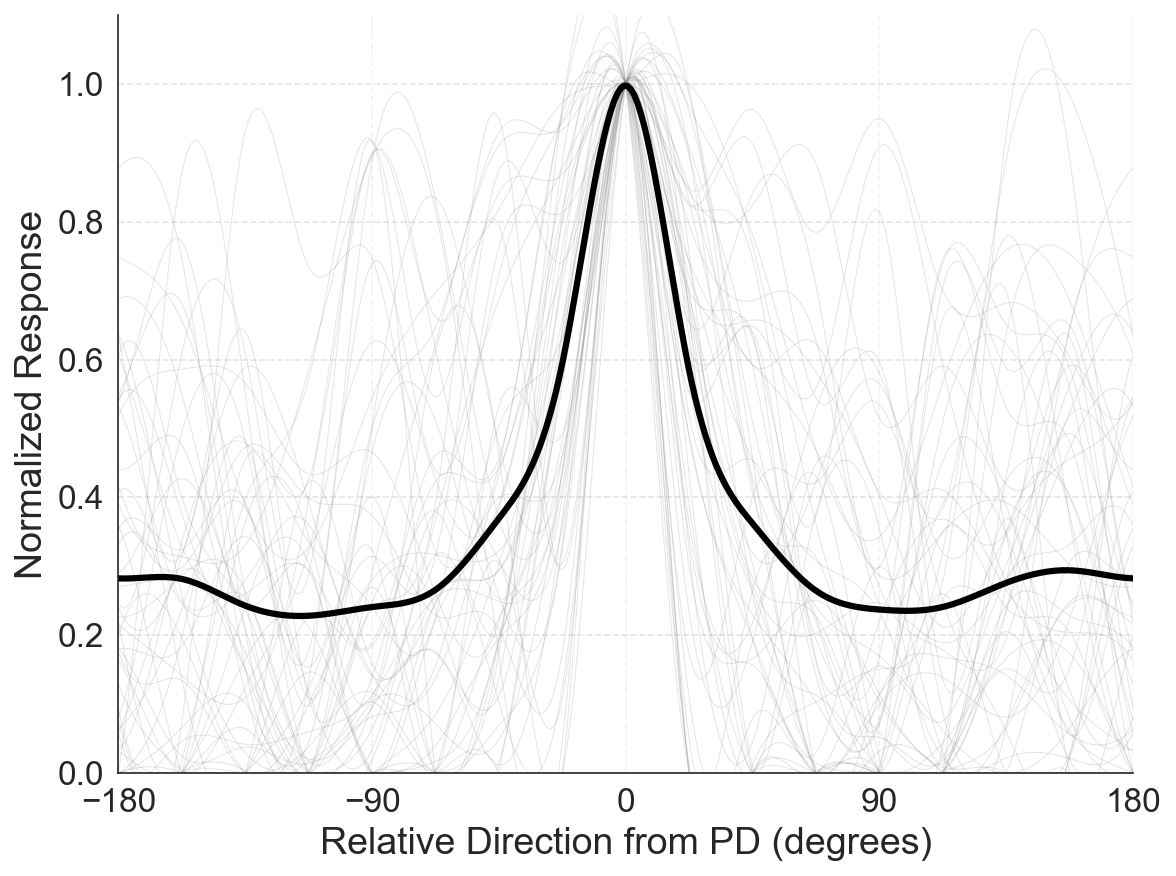

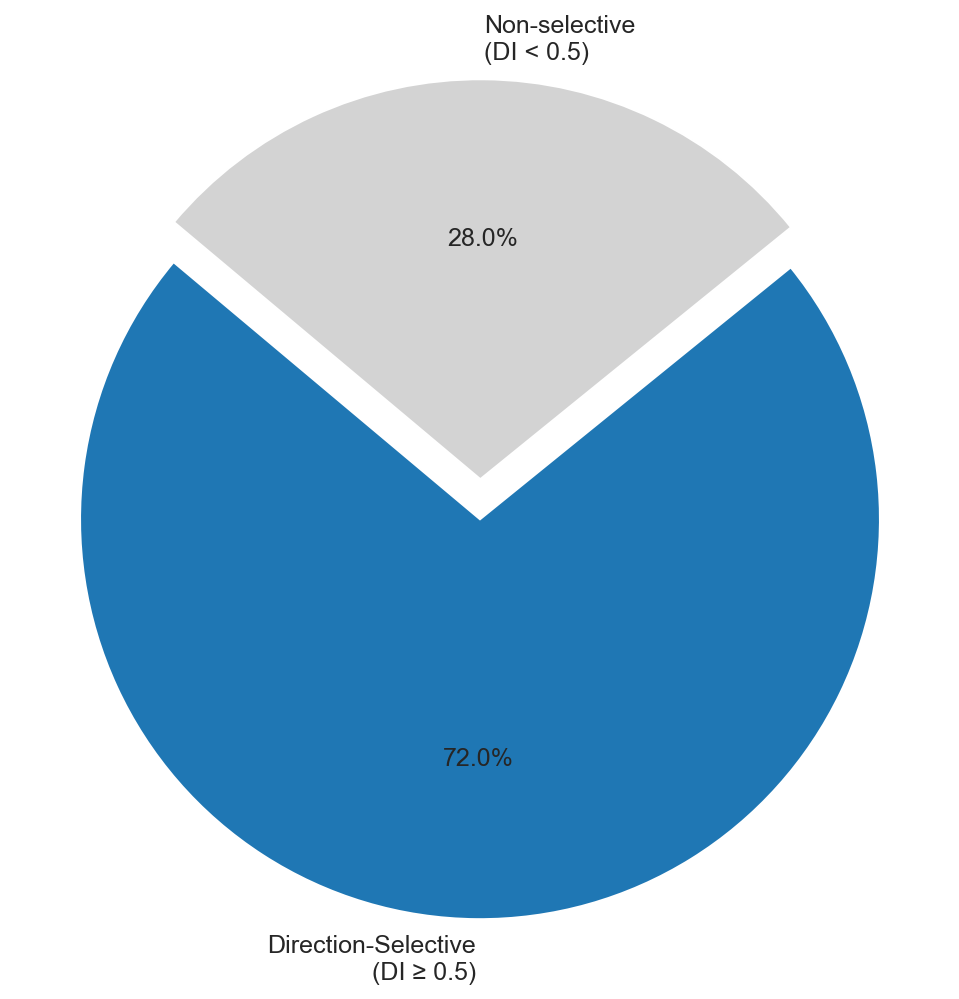

In [ ]:
mt_responses = []
for i in range(16):
    mt_responses.append(features[i]['layer3_1'][0].detach().numpy())

mt_activations = np.array(mt_responses).reshape(16, -1)
plot_population_tuning_curve(mt_activations)

In [ ]:
def interpolate_nan_2d(data):
    x = np.arange(0, data.shape[1])
    y = np.arange(0, data.shape[0])
    mask = ~np.isnan(data)
    xx, yy = np.meshgrid(x, y)
    
    points = np.array( (yy[mask], xx[mask]) ).T
    values = data[mask]
    data_interpolated = interpolate.griddata(points, values, (yy, xx), method='cubic')
    
    return data_interpolated

In [ ]:
responses = []
for i in range(16):
    responses.append(features[i]['layer3_1'][0].detach().numpy())

coordinates = features[1]['layer3_1'][1].coordinates.numpy()
responses = np.array(responses)

preference = np.argmax(responses, axis=0)

In [13]:
from utils.smoother import Smoother, KernelParams

kernel_params = KernelParams(width=.05, stride=0.01)
smoother = Smoother(kernel_params=kernel_params, verbose=True)

smoothed = smoother(coordinates, preference.ravel()*22.5, high=360)
smoothed = interpolate_nan_2d(smoothed)

rows: 100%|██████████| 701/701 [00:35<00:00, 19.69it/s]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

def analyze_pinwheels(pref_dir_matrix, is_degree=True, sigma=1.0):
    data = np.mod(pref_dir_matrix, 360.0) if is_degree else np.mod(pref_dir_matrix, 2*np.pi)
    phi = np.deg2rad(data) if is_degree else data
    
    if sigma > 0:
        complex_data = np.exp(1j * phi)
        smoothed = gaussian_filter(complex_data.real, sigma) + 1j * gaussian_filter(complex_data.imag, sigma)
        phi = np.angle(smoothed)

    rows, cols = phi.shape
    charge_map = np.zeros((rows-1, cols-1))

    for i in range(rows - 1):
        for j in range(cols - 1):
            angles = [phi[i, j], phi[i, j+1], phi[i+1, j+1], phi[i+1, j]]
            delta_sum = 0
            for k in range(4):
                diff = angles[(k+1)%4] - angles[k]
                diff = (diff + np.pi) % (2 * np.pi) - np.pi
                delta_sum += diff
            
            charge = delta_sum / (2 * np.pi)
            if np.abs(charge) > 0.5: 
                charge_map[i, j] = np.sign(charge)

    pos_centers = np.argwhere(charge_map > 0.5) 
    neg_centers = np.argwhere(charge_map < -0.5)
    
    num_pinwheels = len(pos_centers) + len(neg_centers)
    density = num_pinwheels / (rows * cols)
    
 
    dy, dx = np.gradient(phi)
    dx = (dx + np.pi/2) % np.pi - np.pi/2
    dy = (dy + np.pi/2) % np.pi - np.pi/2
    grad_mag = np.sqrt(dx**2 + dy**2)
    avg_gradient = np.mean(grad_mag)
    hist_values = np.rad2deg(grad_mag).ravel()
    hist_weights = np.ones_like(hist_values) * 100.0 / hist_values.size
    plt.hist(hist_values, bins=18, range=(0, 180), weights=hist_weights, color='gray', alpha=0.7)
    plt.xlim(0, 180)
    plt.ylim(0, 80)

    plt.figure(figsize=(7, 6))
    
    plot_data = np.mod(np.rad2deg(phi), 360) 
    im = plt.imshow(plot_data, cmap='hsv', origin='lower', interpolation='gaussian', vmin=0, vmax=360)
    print(np.max(plot_data), np.min(plot_data))
    plt.axis('off')
    
    if len(pos_centers) > 0:
        plt.scatter(pos_centers[:,1], pos_centers[:,0], 
                    c='white', edgecolors='black', s=25, linewidths=.5,
                    marker='o', label='+1 Charge (CW)')
                
    if len(neg_centers) > 0:
        plt.scatter(neg_centers[:,1], neg_centers[:,0], 
                    c='black', edgecolors='white', s=25, linewidths=.5,
                    marker='o', label='-1 Charge (CCW)')

    plt.colorbar(im, fraction=0.046, pad=0.04)
    
    plt.tight_layout()
    plt.show()

    return {
        "num_pinwheels": num_pinwheels,
        "num_positive": len(pos_centers),
        "num_negative": len(neg_centers),
        "pinwheel_density": density,
        "average_gradient": avg_gradient,
        "pos_centers": pos_centers,
        "neg_centers": neg_centers
    }, plot_data

359.2429711117148 1.268561942885211


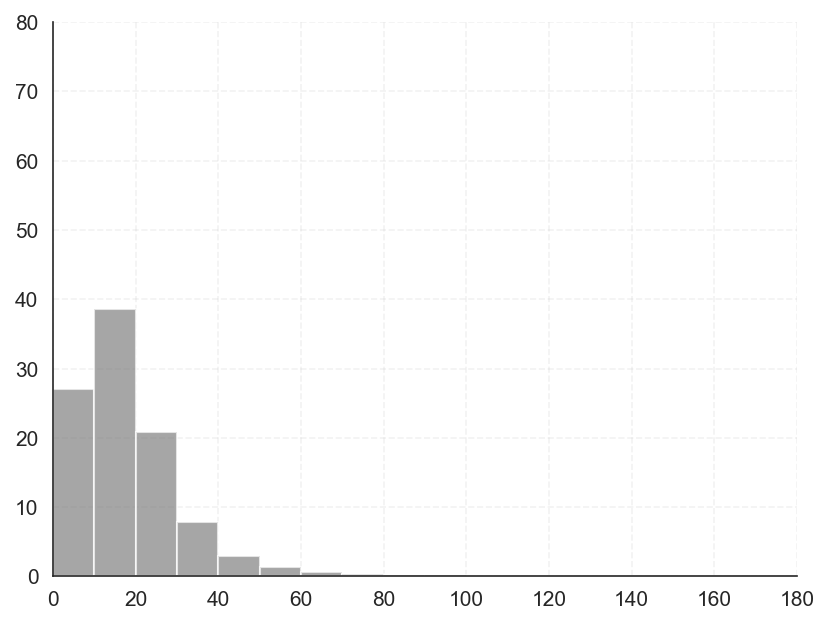

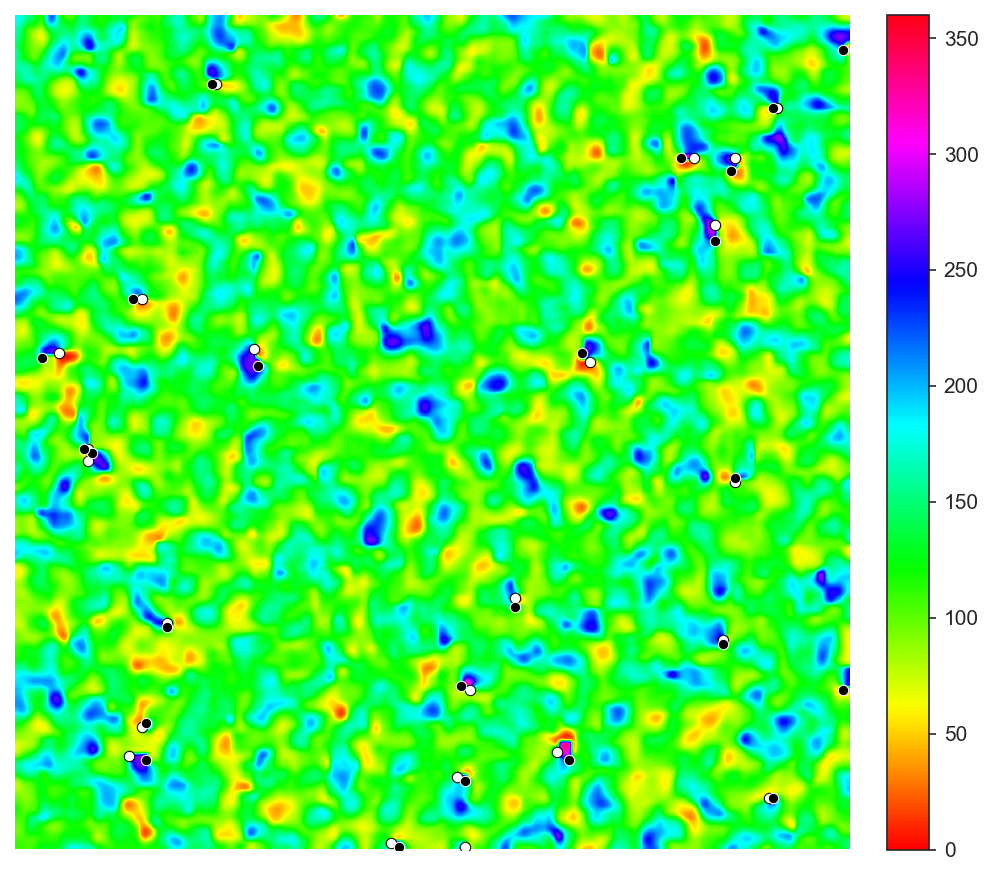

{'num_pinwheels': 47, 'num_positive': 23, 'num_negative': 24, 'pinwheel_density': 0.0011633375411499716, 'average_gradient': np.float64(0.31795121782967906), 'pos_centers': array([[  0, 108],
       [  1,  90],
       [ 12, 181],
       [ 17, 106],
       [ 22,  27],
       [ 23, 130],
       [ 29,  30],
       [ 38, 109],
       [ 50, 170],
       [ 54,  36],
       [ 60, 120],
       [ 88, 173],
       [ 93,  17],
       [ 96,  17],
       [117, 138],
       [119,  10],
       [120,  57],
       [132,  30],
       [150, 168],
       [166, 163],
       [166, 173],
       [178, 183],
       [184,  48]]), 'neg_centers': array([[  0,  92],
       [ 12, 182],
       [ 16, 108],
       [ 21,  31],
       [ 21, 133],
       [ 30,  31],
       [ 38, 199],
       [ 39, 107],
       [ 49, 170],
       [ 53,  36],
       [ 58, 120],
       [ 89, 173],
       [ 95,  18],
       [ 96,  16],
       [116,  58],
       [118,   6],
       [119, 136],
       [132,  28],
       [146, 168],
       [163,

(np.float64(-0.5), np.float64(9.5), np.float64(9.5), np.float64(-0.5))

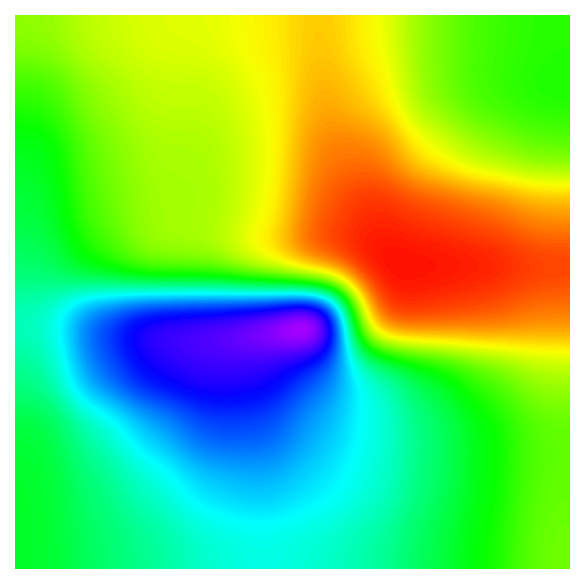

In [ ]:
results, plot_data = analyze_pinwheels(smoothed[250:-250, 250:-250], is_degree=True, sigma=.9)
print(results)